# Activity8.02: Interactive European city initial filter

LU MENGJIE - MC643920

CARTO now requires an API key. With user approval, Esri public light/dark gray tiles replace CARTO, while the custom HOT provider is retained. The bundled official Geoplotlib source has Python 3 / NumPy / SciPy compatibility fixes; it is not a replacement plotting library.

## Activity8.02 - 01. Read and filter Europe

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../../Support').resolve()))
import course_maps
import geoplotlib
import pandas as pd
import numpy as np
from geoplotlib.utils import DataAccessObject, BoundingBox, read_csv
from IPython.display import display
DATA = Path('../../Datasets')
print('LU MENGJIE | MC643920 | Suggested Exercise 08')
print('Public Esri gray basemaps replace key-protected CARTO; HOT is the custom provider.')
dataset = pd.read_csv(DATA/'world_cities_pop.csv', low_memory=False)
display(dataset.head())
print(dataset.dtypes)
dataset = dataset.rename(columns={'Latitude':'lat','Longitude':'lon'})
print('All records:',len(dataset))
europe_country_codes=['al','ad','at','by','be','ba','bg','hr','cy','cz','dk','ee','fo','fi','fr','de','gi','gr','hu','is','ie','im','it','xk','lv','li','lt','lu','mk','mt','md','mc','me','nl','no','pl','pt','ro','sm','rs','sk','si','es','se','ch','ua','gb','va']
europe_data=dataset[dataset.Country.isin(europe_country_codes)].copy()
print('Europe records:',len(europe_data))
z=europe_data[europe_data.City.str.upper().str.startswith('Z',na=False)].copy()
print('Z records:',len(z))
display(z.head())

LU MENGJIE | MC643920 | Suggested Exercise 08
Public Esri gray basemaps replace key-protected CARTO; HOT is the custom provider.


,Country,City,AccentCity,Region,Population,Latitude,Longitude
0,ad,aixas,Aixàs,06,NaN,42.483333,1.466667
1,ad,aixirivali,Aixirivali,06,NaN,42.466667,1.500000
2,ad,aixirivall,Aixirivall,06,NaN,42.466667,1.500000
3,ad,aixirvall,Aixirvall,06,NaN,42.466667,1.500000
4,ad,aixovall,Aixovall,06,NaN,42.466667,1.483333


Country           str
City              str
AccentCity        str
Region            str
Population    float64
Latitude      float64
Longitude     float64
dtype: object
All records: 3173958
Europe records: 682348
Z records: 13218


,Country,City,AccentCity,Region,Population,lat,lon
104206,al,zaane,ZÄane,44,NaN,40.932778,19.783056
104207,al,zabarzani,Zabarzani,40,NaN,40.427778,20.269167
104208,al,zabarzan,Zabarzan,40,NaN,40.427778,20.269167
104209,al,zaberzane,Zabërzanë,40,NaN,40.427778,20.269167
104210,al,zaberzan i siperm,Zaberzan i Sipërm,40,NaN,40.427778,20.269167


## Activity8.02 - 02. Z dot map with city tooltip

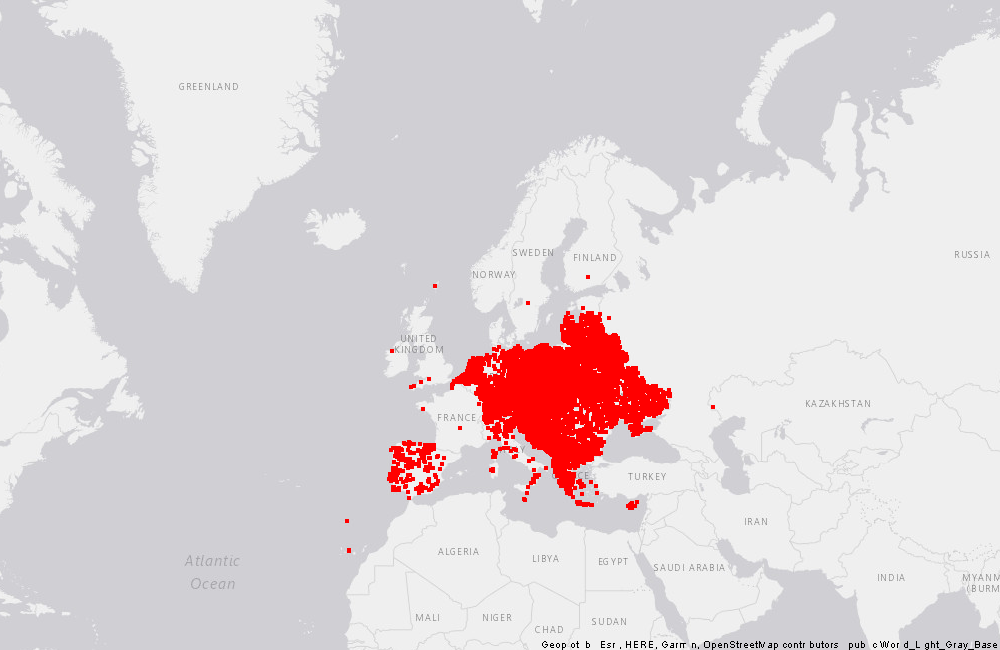

In [2]:
europe_bbox=BoundingBox(north=71,west=-25,south=34,east=45)
geoplotlib.dot(DataAccessObject(z),f_tooltip=lambda r:r['Country']+' - '+r['City'])
geoplotlib.set_bbox(europe_bbox)
course_maps.snapshot('z_dots',hover=(float(z.iloc[0].lon),float(z.iloc[0].lat)))

## Activity8.02 - 03. Z Voronoi

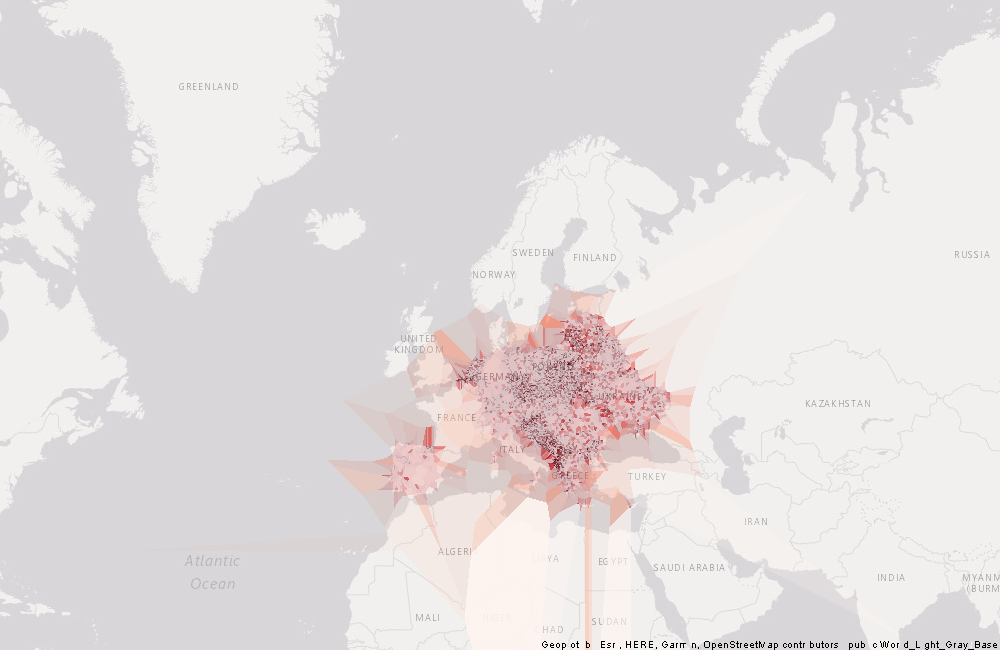

In [3]:
geoplotlib.voronoi(DataAccessObject(z),cmap='Reds_r',alpha=50)
geoplotlib.set_bbox(europe_bbox)
course_maps.snapshot('z_voronoi')

## Activity8.02 - 04. Define interactive FilterLayer

In [4]:
import string
from pyglet.window import key
from geoplotlib.layers import BaseLayer
from geoplotlib.core import BatchPainter
class FilterLayer(BaseLayer):
    def __init__(self,data,bbox):
        self.data=data
        self.view=bbox
        self.start_letters=list(string.ascii_uppercase)
        self.start_letter=0
    def invalidate(self,proj):
        letter=self.start_letters[self.start_letter]
        mask=np.array([str(city).upper().startswith(letter) for city in self.data['City']])
        selected=self.data.where(mask)
        self.count=len(selected)
        self.painter=BatchPainter()
        self.painter.set_color([0,0,255,255])
        x,y=proj.lonlat_to_screen(selected['lon'],selected['lat'])
        self.painter.points(x,y,2)
    def draw(self,proj,mouse_x,mouse_y,ui_manager):
        self.painter.batch_draw()
        ui_manager.info('Displaying cities starting with '+self.start_letters[self.start_letter]+f' ({self.count})')
    def on_key_release(self,key_symbol,modifiers):
        if key_symbol==key.RIGHT:
            self.start_letter=(self.start_letter+1)%len(self.start_letters)
            return True
        if key_symbol==key.LEFT:
            self.start_letter=(self.start_letter-1)%len(self.start_letters)
            return True
        return False
    def bbox(self):
        return self.view

## Activity8.02 - 05. Test real key events A to C and wraparound

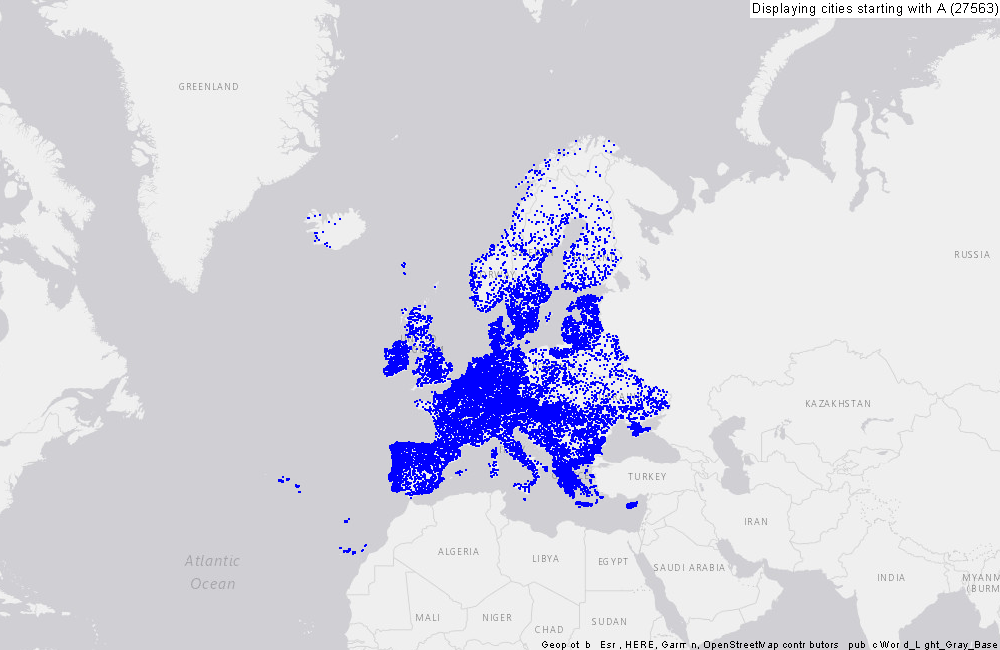

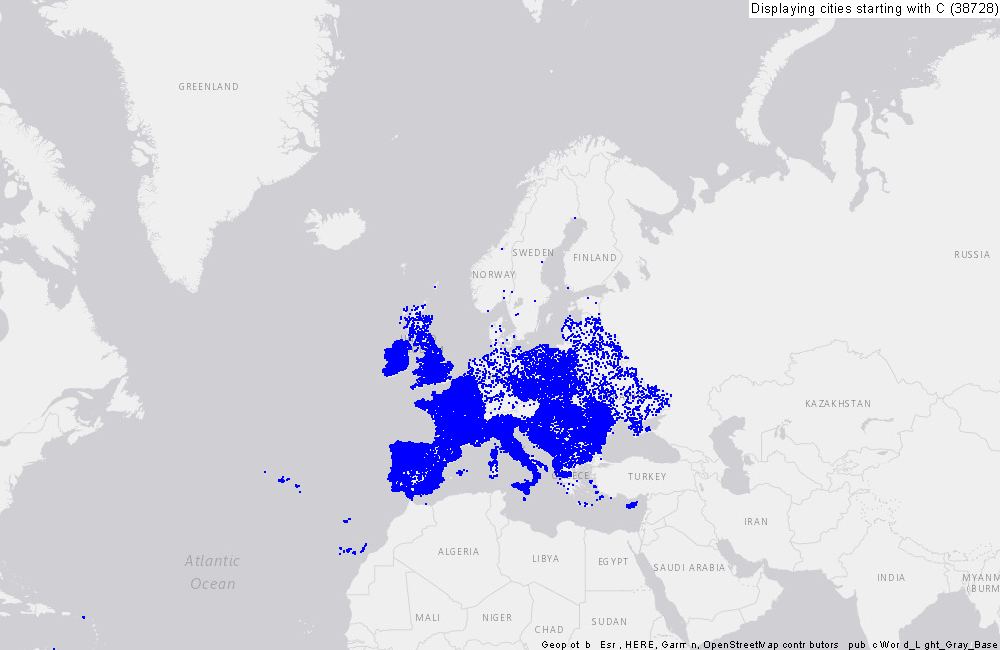

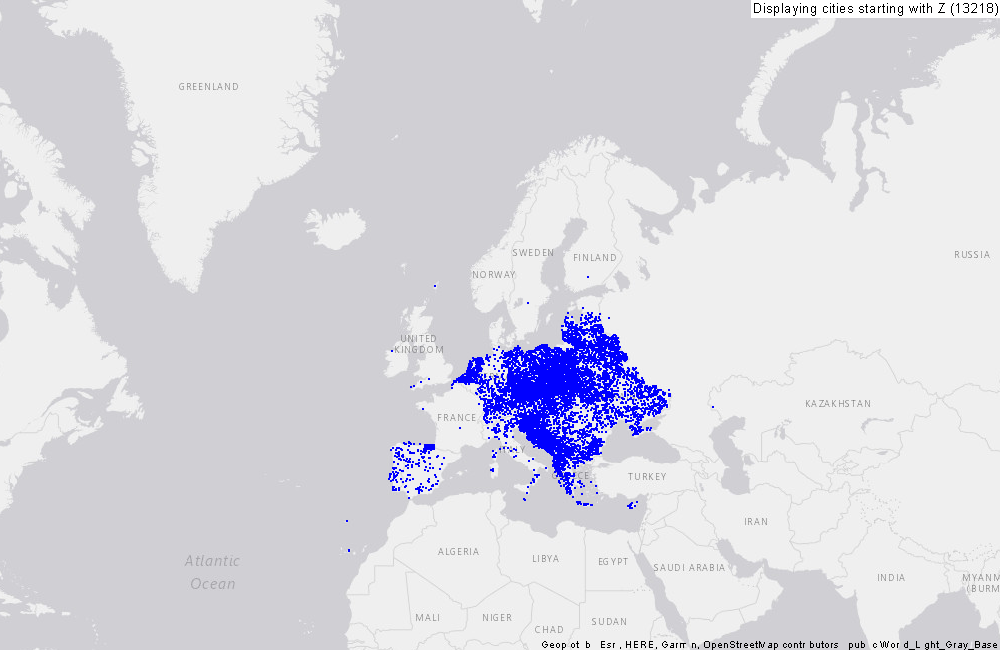

Real key-event checks passed: A -> RIGHT twice -> C; C -> LEFT three times -> Z.


In [5]:
layer=FilterLayer(DataAccessObject(europe_data),europe_bbox)
geoplotlib.add_layer(layer)
course_maps.keyboard_demo('letter_filter',layer)
# For manual keyboard use: geoplotlib.add_layer(FilterLayer(DataAccessObject(europe_data),europe_bbox)); geoplotlib.show()